# Exercise 3.2 &mdash; Key-based LSB audio steganography

This notebook hides the secret message **"It always seems impossible until it's done"** inside `Ex3_sound5.wav` using a more sophisticated variant of Least-Significant-Bit (LSB) audio steganography, and provides the matching algorithm to extract it again.

Two enhancements over plain, consecutive single-bit LSB embedding are combined:

1. **Non-consecutive samples chosen by a secret key.** A single integer *stego key* seeds a pseudo-random permutation of the sample indices. The message bits are scattered across the audio in that pseudo-random order. Because both parties regenerate the same permutation from the key, **only the key has to be shared** &mdash; not the list of positions.
2. **More than one least significant bit.** Each selected sample carries `n_lsb` bits (we use 2), doubling capacity per sample while staying inaudible.

A small **32-bit length header** is embedded first so that extraction is fully self-contained: given only the key, the extractor learns how many bits to read and stops on its own.

## 1. Imports and configuration

`wave` reads/writes the WAV container, `random` provides the key-seeded permutation, `numpy` lets us manipulate the 16-bit samples efficiently, and `matplotlib` is used at the end to visualise how little the waveform changes.

In [1]:
import wave
import random
import math
import os
import numpy as np
import matplotlib.pyplot as plt

# --- Configuration ---------------------------------------------------------
INPUT_WAV  = '../assets/Ex3_files/Ex3_sound5.wav'   # cover audio
OUTPUT_WAV = 'out/Ex3_sound5_embedded.wav'          # stego audio (message hidden inside)
MESSAGE    = "It always seems impossible until it's done"
KEY        = 20240703      # the ONLY secret shared between sender and receiver
N_LSB      = 2             # least-significant bits used per selected sample
HEADER_BITS = 32           # fixed-width header storing the message length in bytes

os.makedirs('out', exist_ok=True)

## 2. Helper functions

`_read_samples` returns the audio as a mutable NumPy array of signed 16-bit integers together with the original WAV parameters (so the output keeps the exact same format).

`_key_order` is the heart of the technique: it turns the secret key into a deterministic pseudo-random ordering of every sample index. Sender and receiver call it with the same key and obtain the *same* order, so the receiver never needs the explicit position list. Because the whole index range is shuffled once, any prefix of the result is stable &mdash; the extractor can read the header from the first few positions before it even knows the full message length.

In [2]:
def _read_samples(path):
    """Read a WAV file into an int16 NumPy array plus its parameters."""
    with wave.open(path, 'rb') as wav:
        params = wav.getparams()
        if params.sampwidth != 2:
            raise ValueError(
                f'Only 16-bit PCM WAV is supported, got {params.sampwidth * 8}-bit.')
        raw = wav.readframes(params.nframes)
    # WAV PCM samples are little-endian signed 16-bit integers.
    samples = np.frombuffer(raw, dtype=np.int16).copy()
    return samples, params


def _key_order(n_samples, key):
    """Deterministic pseudo-random ordering of sample indices, derived from the key."""
    rng = random.Random(key)
    order = list(range(n_samples))
    rng.shuffle(order)
    return order

## 3. Embedding algorithm

The `embed_message` function:

1. Encodes the message as UTF-8 bytes and builds a bit-stream of **`[32-bit length header] + [message bits]`**. The header stores the message length in **bytes**, so multi-byte UTF-8 characters are handled correctly.
2. Computes how many samples (*slots*) are needed &mdash; each slot stores `n_lsb` bits &mdash; and checks the audio is large enough.
3. Uses the key-seeded ordering to pick that many **non-consecutive** samples.
4. Clears the low `n_lsb` bits of each chosen sample and writes the next group of message bits into them (vectorised with NumPy).
5. Writes the result back out with the original WAV parameters, and reports how many samples changed.

In [3]:
def embed_message(input_wav, output_wav, message, key, n_lsb=N_LSB):
    samples, params = _read_samples(input_wav)

    # 1. Message -> bit-stream, prefixed with a 32-bit length header (in bytes).
    msg_bytes = message.encode('utf-8')
    header = format(len(msg_bytes), f'0{HEADER_BITS}b')
    payload = ''.join(format(byte, '08b') for byte in msg_bytes)
    bitstream = header + payload

    # 2. How many samples do we need? (n_lsb bits per sample.)
    n_slots = math.ceil(len(bitstream) / n_lsb)
    if n_slots > len(samples):
        raise ValueError(
            f'Message needs {n_slots} samples but audio only has {len(samples)}.')

    # 3. Key-seeded pseudo-random, non-consecutive positions.
    positions = np.array(_key_order(len(samples), key)[:n_slots], dtype=np.int64)

    # 4. Split the bit-stream into n_lsb-sized groups and write them in.
    groups = [bitstream[i:i + n_lsb].ljust(n_lsb, '0')
              for i in range(0, len(bitstream), n_lsb)]
    values = np.array([int(g, 2) for g in groups], dtype=np.int32)

    work = samples.astype(np.int32)                 # avoid int16 sign issues while masking
    clear_mask = ~((1 << n_lsb) - 1)                # e.g. ...11111100 for n_lsb = 2
    work[positions] = (work[positions] & clear_mask) | values

    changed = int(np.count_nonzero(work != samples.astype(np.int32)))
    max_delta = int(np.max(np.abs(work - samples.astype(np.int32))))

    # 5. Write the stego audio with the original format parameters.
    with wave.open(output_wav, 'wb') as wav:
        wav.setparams(params)
        wav.writeframes(work.astype(np.int16).tobytes())

    return {'slots': n_slots, 'capacity': len(samples),
            'changed': changed, 'max_delta': max_delta}

## 4. Extraction algorithm

`extract_message` performs the exact inverse using **only the stego file and the key**:

1. Regenerate the same key-seeded ordering of sample indices.
2. Read the low `n_lsb` bits of the first few samples to recover the **32-bit length header**, giving the message length in bytes.
3. Read exactly enough further samples for `header + message`, drop the header bits, and decode the remaining bytes back into text as UTF-8.

In [4]:
def extract_message(stego_wav, key, n_lsb=N_LSB):
    samples, _ = _read_samples(stego_wav)
    mask = (1 << n_lsb) - 1
    order = _key_order(len(samples), key)

    def read_bits(count_slots):
        picked = samples[order[:count_slots]]
        return ''.join(format(int(v) & mask, f'0{n_lsb}b') for v in picked)

    # 1-2. Recover the length header first.
    header_slots = math.ceil(HEADER_BITS / n_lsb)
    header_bits = read_bits(header_slots)[:HEADER_BITS]
    msg_len = int(header_bits, 2)                    # message length in bytes

    # 3. Read header + message, then decode the message bytes as UTF-8.
    total_bits = HEADER_BITS + msg_len * 8
    n_slots = math.ceil(total_bits / n_lsb)
    all_bits = read_bits(n_slots)
    msg_bits = all_bits[HEADER_BITS:HEADER_BITS + msg_len * 8]
    msg_bytes = bytes(int(msg_bits[i:i + 8], 2)
                      for i in range(0, len(msg_bits), 8))
    return msg_bytes.decode('utf-8')

## 5. Embed the secret message

In [5]:
stats = embed_message(INPUT_WAV, OUTPUT_WAV, MESSAGE, KEY, N_LSB)

print(f'Secret message : {MESSAGE!r}')
print(f'Stego key      : {KEY}')
print(f'Bits per sample: {N_LSB}')
print(f'Samples used   : {stats["slots"]} of {stats["capacity"]} '
      f'({100 * stats["slots"] / stats["capacity"]:.3f}% of capacity)')
print(f'Samples changed: {stats["changed"]} (max amplitude change +/-{stats["max_delta"]})')
print(f'Written to     : {OUTPUT_WAV}')

Secret message : "It always seems impossible until it's done"
Stego key      : 20240703
Bits per sample: 2
Samples used   : 184 of 407280 (0.045% of capacity)
Samples changed: 132 (max amplitude change +/-3)
Written to     : out/Ex3_sound5_embedded.wav


## 6. Extract the secret message

Extraction needs nothing but the stego file and the key. We also confirm the round-trip is loss-less, and that a **wrong key** recovers only noise &mdash; demonstrating that the key genuinely protects the hidden message.

In [6]:
recovered = extract_message(OUTPUT_WAV, KEY, N_LSB)
print(f'Extracted message: {recovered!r}')
print(f'Matches original : {recovered == MESSAGE}')

# A wrong key selects the wrong samples: the recovered bytes are noise and
# usually aren't even valid UTF-8, so decoding fails outright.
try:
    wrong = extract_message(OUTPUT_WAV, KEY + 1, N_LSB)
    print(f'\nWith wrong key   : {wrong[:30]!r} ...  (matches: {wrong == MESSAGE})')
except UnicodeDecodeError:
    print('\nWith wrong key   : decoding failed (invalid UTF-8) — message not recoverable')

Extracted message: "It always seems impossible until it's done"
Matches original : True

With wrong key   : decoding failed (invalid UTF-8) — message not recoverable


## 7. How much did the audio change?

Only a few dozen samples are altered, and each by at most a couple of quantisation steps out of 65,536 &mdash; far below the threshold of hearing. The plot marks the handful of modified samples on the waveform.

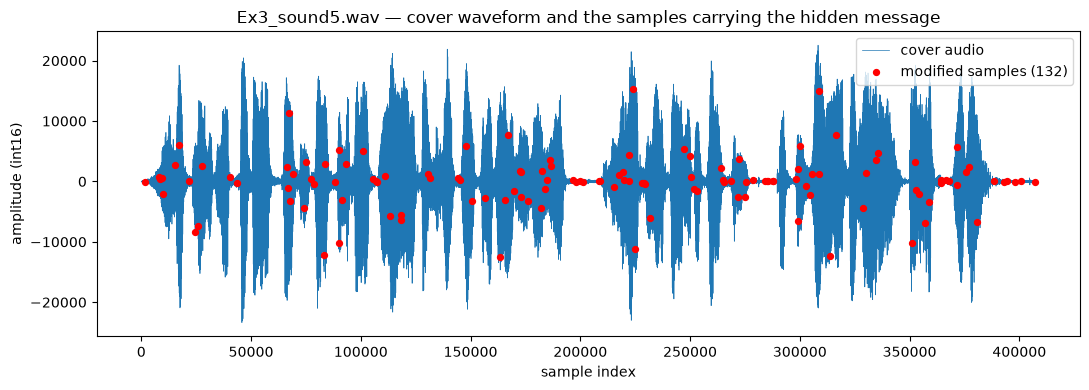

In [7]:
original, _ = _read_samples(INPUT_WAV)
stego, _ = _read_samples(OUTPUT_WAV)
diff_idx = np.nonzero(original != stego)[0]

plt.figure(figsize=(11, 4))
plt.plot(original, linewidth=0.5, label='cover audio')
plt.scatter(diff_idx, stego[diff_idx], color='red', s=18, zorder=3,
            label=f'modified samples ({len(diff_idx)})')
plt.title('Ex3_sound5.wav \u2014 cover waveform and the samples carrying the hidden message')
plt.xlabel('sample index')
plt.ylabel('amplitude (int16)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 8. Summary

The message *"It always seems impossible until it's done"* was embedded into `Ex3_sound5.wav` and recovered without error. The scheme improves on basic LSB steganography by:

* **Scattering** the bits across non-consecutive samples in a **key-dependent** pseudo-random order &mdash; the sender and receiver share only a single integer key, not the positions.
* Packing **2 bits per sample** (`n_lsb`), which increases capacity while keeping the change inaudible.
* Prefixing a **self-describing length header**, so the extractor stops on its own without being told the message size.

Without the correct key an attacker cannot even locate the bits, let alone read them, and the audible impact on the cover file is negligible.